# Nigeria 2030 — Analysis notebook

Self-contained. Reads `analysis/metrics.csv`. Every figure is one cell you can re-run.


In [12]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

ROOT = Path.cwd()
if ROOT.name == 'analysis':
    REPO = ROOT.parent
else:
    REPO = ROOT
    ROOT = REPO / 'analysis'

METRICS_CSV = ROOT / 'metrics.csv'
FIG_DIR = ROOT / 'output' / 'figures'
TBL_DIR = ROOT / 'output' / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False,
})

PALETTE = {
    'solar': '#f4a300', 'onwind': '#3d9970', 'offwind': '#2e86ab',
    'hydro': '#1e6fa8', 'ror': '#5fa8d3', 'PHS': '#7fb3d5',
    'CCGT': '#c0392b', 'OCGT': '#e67e22', 'oil': '#5d4037',
    'coal': '#424242', 'biomass': '#8bc34a', 'battery': '#9b59b6',
    'load shedding': '#000000',
}
CARRIER_ORDER = ['solar','onwind','offwind','hydro','ror','PHS','battery',
                 'CCGT','OCGT','oil','coal','biomass','load shedding']
LABELS = {'solar':'Solar','onwind':'Wind','offwind':'Offwind','hydro':'Hydro',
          'ror':'RoR','PHS':'PHS','battery':'Battery','CCGT':'CCGT','OCGT':'OCGT',
          'oil':'Oil','coal':'Coal','biomass':'Biomass','load shedding':'Load shedding'}

def savefig(fig, name):
    pdf = FIG_DIR / f'{name}.pdf'
    png = FIG_DIR / f'{name}.png'
    fig.savefig(pdf); fig.savefig(png); plt.close(fig)
    return pdf

def short(s):
    for p in ('cap_exp_2030_', 'config.nigeria.2030_'):
        if s.startswith(p): return s[len(p):]
    return s

def pivot(df, kind='cap'):
    suffix = '_gw' if kind=='cap' else '_twh'
    cols = [c for c in df.columns if c.startswith(kind+'_') and c.endswith(suffix)]
    p = df.set_index('run_name')[cols].copy()
    p.columns = [c.replace(kind+'_','').replace(suffix,'') for c in cols]
    return p

df = pd.read_csv(METRICS_CSV)
print(f'Loaded {len(df)} scenarios, {len(df.columns)} columns')
print(df[['run_name','group','wacc_solar','ndc','gas_usd_per_mmbtu']].to_string(index=False))


Loaded 23 scenarios, 37 columns
                                     run_name group  wacc_solar   ndc  gas_usd_per_mmbtu
                    cap_exp_2030_uniform_wacc     B      0.1000 False               3.39
                      cap_exp_2030_split_wacc     B      0.1379 False               3.39
         config.nigeria.2030_B3_high_fin_2000     B      0.2000 False               3.39
             config.nigeria.2030_C1_wacc_0700     C      0.0700 False               3.39
             config.nigeria.2030_C2_wacc_0900     C      0.0900 False               3.39
             config.nigeria.2030_C3_wacc_1100     C      0.1100 False               3.39
             config.nigeria.2030_C4_wacc_1200     C      0.1200 False               3.39
             config.nigeria.2030_C5_wacc_1300     C      0.1300 False               3.39
             config.nigeria.2030_C6_wacc_1379     C      0.1379 False               3.39
             config.nigeria.2030_C7_wacc_1468     C      0.1468 False         

## Fig 5.1 — Installed capacity by scenario

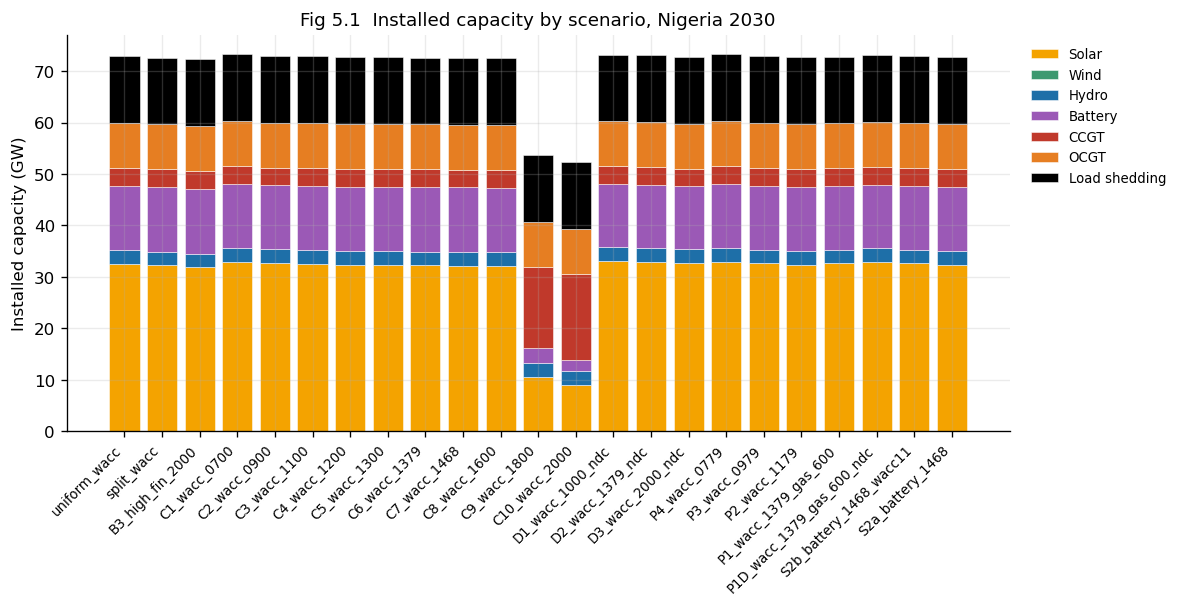

PosixPath('/Users/fowfloi/Documents/pypsa-earth/analysis/output/figures/fig_5_01_capacity.pdf')

In [13]:
cap = pivot(df, 'cap').loc[df['run_name']]
carriers = [c for c in CARRIER_ORDER if c in cap.columns and cap[c].sum() > 0]
cap = cap[carriers]

fig, ax = plt.subplots(figsize=(12, 5.5))
bottom = pd.Series(0.0, index=cap.index)
for c in carriers:
    ax.bar(range(len(cap)), cap[c].values, bottom=bottom.values,
           color=PALETTE.get(c,'#999'), label=LABELS.get(c,c),
           width=0.8, edgecolor='white', linewidth=0.3)
    bottom += cap[c].fillna(0)
ax.set_xticks(range(len(cap)))
ax.set_xticklabels([short(r) for r in cap.index], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Installed capacity (GW)')
ax.set_title('Fig 5.1  Installed capacity by scenario, Nigeria 2030')
ax.legend(loc='upper left', bbox_to_anchor=(1.01,1), fontsize=8)
fig.subplots_adjust(right=0.78, bottom=0.28)
plt.show()
savefig(fig, 'fig_5_01_capacity')

## Fig 5.2 — Generation mix by scenario

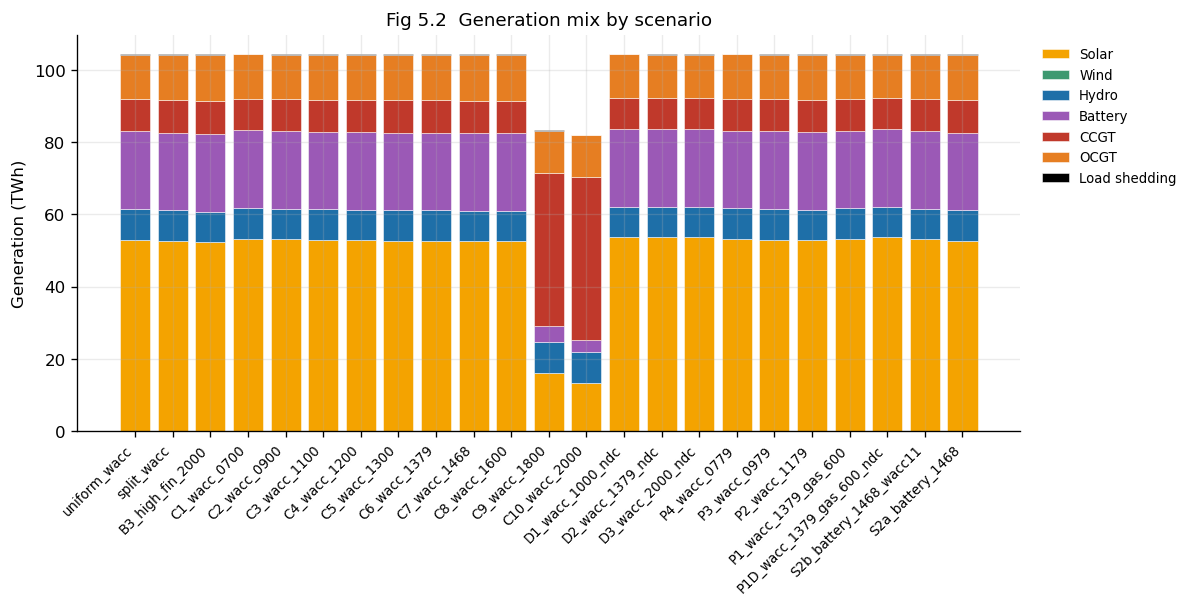

PosixPath('/Users/fowfloi/Documents/pypsa-earth/analysis/output/figures/fig_5_02_generation.pdf')

In [14]:
gen = pivot(df, 'gen').loc[df['run_name']]
carriers = [c for c in CARRIER_ORDER if c in gen.columns and gen[c].sum() > 0]
gen = gen[carriers]

fig, ax = plt.subplots(figsize=(12, 5.5))
bottom = pd.Series(0.0, index=gen.index)
for c in carriers:
    ax.bar(range(len(gen)), gen[c].values, bottom=bottom.values,
           color=PALETTE.get(c,'#999'), label=LABELS.get(c,c),
           width=0.8, edgecolor='white', linewidth=0.3)
    bottom += gen[c].fillna(0)
ax.set_xticks(range(len(gen)))
ax.set_xticklabels([short(r) for r in gen.index], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Generation (TWh)')
ax.set_title('Fig 5.2  Generation mix by scenario')
ax.legend(loc='upper left', bbox_to_anchor=(1.01,1), fontsize=8)
fig.subplots_adjust(right=0.78, bottom=0.28)
plt.show()
savefig(fig, 'fig_5_02_generation')

## Fig 5.3 — WACC sweep, unconstrained vs NDC (the money shot)

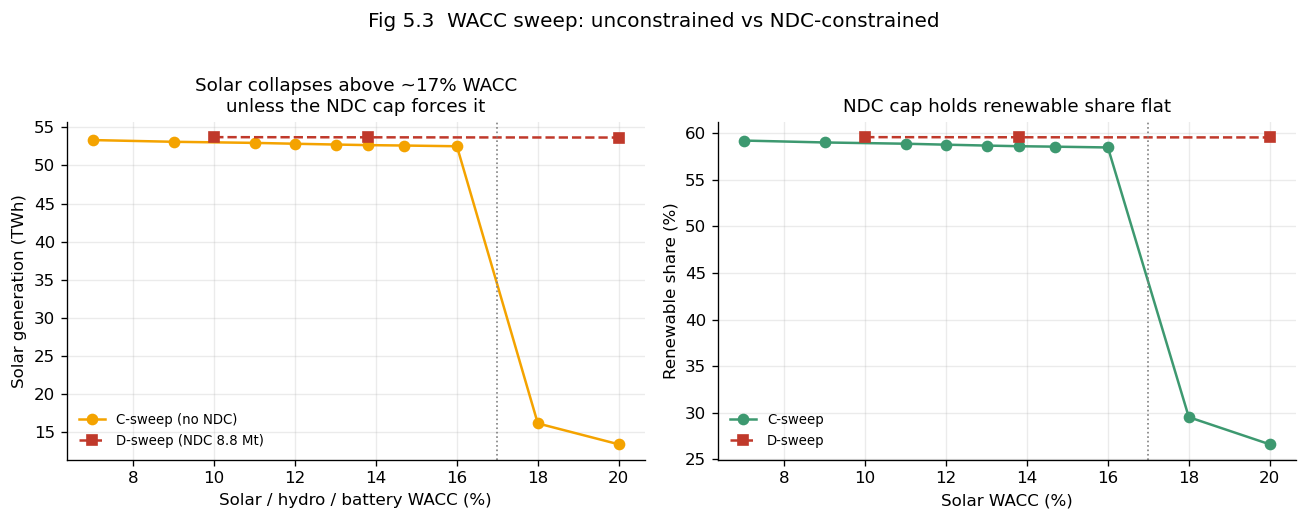

PosixPath('/Users/fowfloi/Documents/pypsa-earth/analysis/output/figures/fig_5_03_wacc_sweep.pdf')

In [15]:
C = df[df['group']=='C'].sort_values('wacc_solar')
D = df[df['group']=='D'].sort_values('wacc_solar')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
ax.plot(100*C['wacc_solar'], C['gen_solar_twh'], 'o-', color=PALETTE['solar'], label='C-sweep (no NDC)')
ax.plot(100*D['wacc_solar'], D['gen_solar_twh'], 's--', color=PALETTE['CCGT'], label='D-sweep (NDC 8.8 Mt)')
ax.axvline(17, color='gray', linestyle=':', linewidth=1)
ax.set_xlabel('Solar / hydro / battery WACC (%)')
ax.set_ylabel('Solar generation (TWh)')
ax.set_title('Solar collapses above ~17% WACC\nunless the NDC cap forces it')
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(100*C['wacc_solar'], 100*C['renewable_share'], 'o-', color=PALETTE['onwind'], label='C-sweep')
ax.plot(100*D['wacc_solar'], 100*D['renewable_share'], 's--', color=PALETTE['CCGT'], label='D-sweep')
ax.axvline(17, color='gray', linestyle=':', linewidth=1)
ax.set_xlabel('Solar WACC (%)')
ax.set_ylabel('Renewable share (%)')
ax.set_title('NDC cap holds renewable share flat')
ax.legend(fontsize=8)

fig.suptitle('Fig 5.3  WACC sweep: unconstrained vs NDC-constrained', y=1.02)
fig.tight_layout()
plt.show()
savefig(fig, 'fig_5_03_wacc_sweep')

## Fig 5.4 — Emissions vs NDC cap

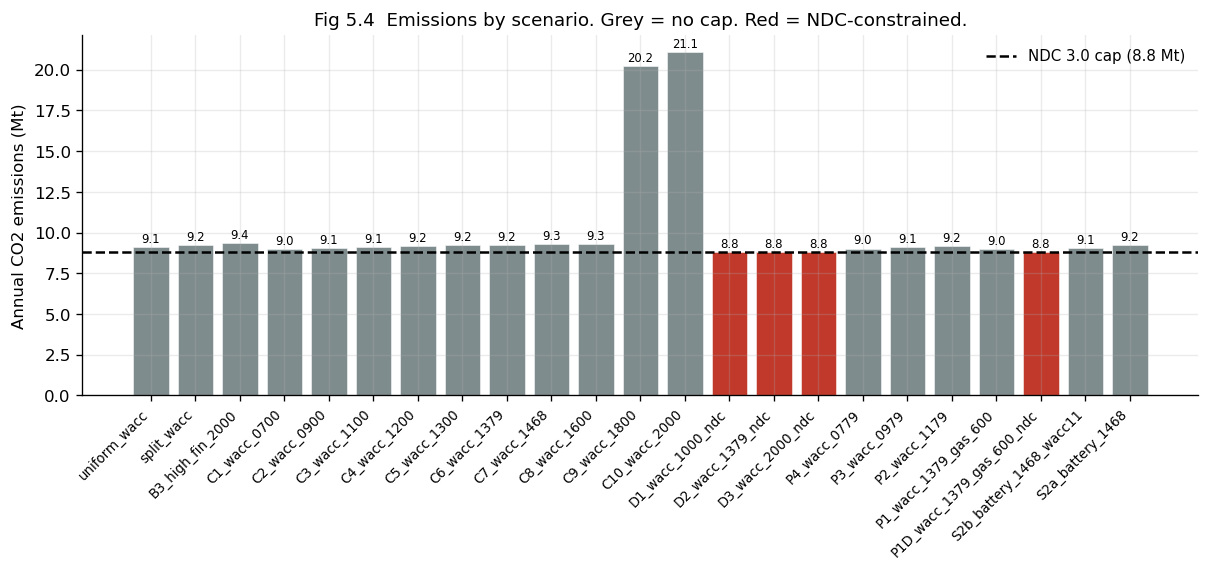

PosixPath('/Users/fowfloi/Documents/pypsa-earth/analysis/output/figures/fig_5_04_emissions.pdf')

In [16]:
d = df.sort_values(['group','wacc_solar','ndc']).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#c0392b' if n else '#7f8c8d' for n in d['ndc']]
ax.bar(range(len(d)), d['emissions_mt'], color=colors, edgecolor='white', linewidth=0.3)
ax.axhline(8.8, color='black', linewidth=1.5, linestyle='--', label='NDC 3.0 cap (8.8 Mt)')
ax.set_xticks(range(len(d)))
ax.set_xticklabels([short(r) for r in d['run_name']], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Annual CO2 emissions (Mt)')
ax.set_title('Fig 5.4  Emissions by scenario. Grey = no cap. Red = NDC-constrained.')
for i, e in enumerate(d['emissions_mt']):
    ax.text(i, e+0.3, f'{e:.1f}', ha='center', fontsize=7)
ax.legend(fontsize=9)
fig.subplots_adjust(bottom=0.28)
plt.show()
savefig(fig, 'fig_5_04_emissions')

## Fig 5.5 — System cost

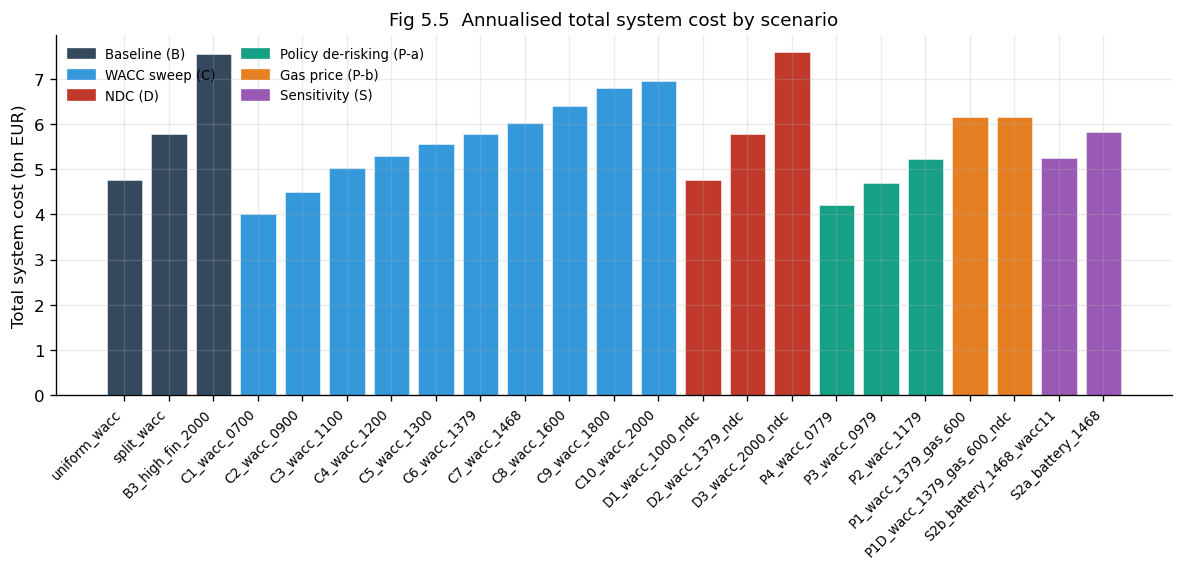

PosixPath('/Users/fowfloi/Documents/pypsa-earth/analysis/output/figures/fig_5_05_system_cost.pdf')

In [17]:
d = df.sort_values(['group','wacc_solar','ndc']).reset_index(drop=True)
cmap = {'B':'#34495e','C':'#3498db','D':'#c0392b','P-a':'#16a085','P-b':'#e67e22','S':'#9b59b6'}

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(d)), d['objective']/1e9,
       color=[cmap.get(g,'#999') for g in d['group']], edgecolor='white', linewidth=0.3)
ax.set_xticks(range(len(d)))
ax.set_xticklabels([short(r) for r in d['run_name']], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Total system cost (bn EUR)')
ax.set_title('Fig 5.5  Annualised total system cost by scenario')
handles = [plt.Rectangle((0,0),1,1,color=v) for v in cmap.values()]
labels = ['Baseline (B)','WACC sweep (C)','NDC (D)','Policy de-risking (P-a)','Gas price (P-b)','Sensitivity (S)']
ax.legend(handles, labels, fontsize=8, loc='upper left', ncol=2)
fig.subplots_adjust(bottom=0.28)
plt.show()
savefig(fig, 'fig_5_05_system_cost')

## Fig 5.7 — Financing gap vs the 7% WACC optimum

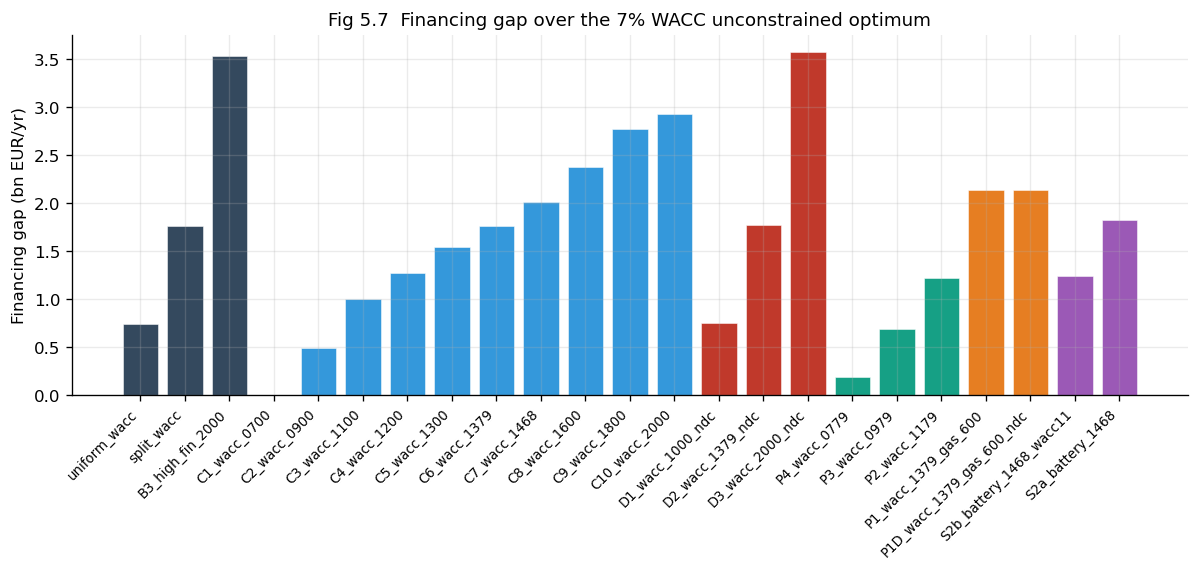

PosixPath('/Users/fowfloi/Documents/pypsa-earth/analysis/output/figures/fig_5_07_financing_gap.pdf')

In [18]:
baseline = df.query("run_name == 'config.nigeria.2030_C1_wacc_0700'")['objective'].iloc[0]
d = df.copy()
d['gap_bn'] = (d['objective'] - baseline) / 1e9
d = d.sort_values(['group','wacc_solar','ndc']).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(d)), d['gap_bn'],
       color=[cmap.get(g,'#999') for g in d['group']], edgecolor='white', linewidth=0.3)
ax.set_xticks(range(len(d)))
ax.set_xticklabels([short(r) for r in d['run_name']], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Financing gap (bn EUR/yr)')
ax.set_title('Fig 5.7  Financing gap over the 7% WACC unconstrained optimum')
fig.subplots_adjust(bottom=0.28)
plt.show()
savefig(fig, 'fig_5_07_financing_gap')

## Fig 5.11 — Gas price vs WACC (non-substitutability)

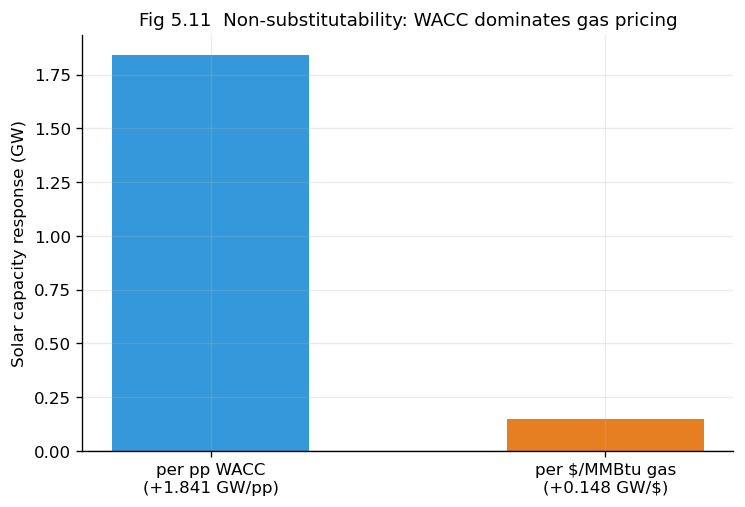

WACC response: +1.841 GW per pp
Gas price response: +0.148 GW per $/MMBtu


In [19]:
dfi = df.set_index('run_name')
C = dfi.loc[[r for r in dfi.index if r.startswith('config.nigeria.2030_C')]].sort_values('wacc_solar')

dwacc_pp = 100*(C['wacc_solar'].iloc[-1] - C['wacc_solar'].iloc[0])
dsolar_wacc_per_pp = (C['cap_solar_gw'].iloc[0] - C['cap_solar_gw'].iloc[-1]) / dwacc_pp

dsolar_gas = dfi.at['config.nigeria.2030_P1_wacc_1379_gas_600','cap_solar_gw'] - \
             dfi.at['config.nigeria.2030_C6_wacc_1379','cap_solar_gw']
gw_per_usd_gas = dsolar_gas / (6.00 - 3.39)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar([0,1], [dsolar_wacc_per_pp, gw_per_usd_gas], color=['#3498db','#e67e22'], width=0.5)
ax.set_xticks([0,1])
ax.set_xticklabels([f'per pp WACC\n({dsolar_wacc_per_pp:+.3f} GW/pp)',
                    f'per $/MMBtu gas\n({gw_per_usd_gas:+.3f} GW/$)'])
ax.set_ylabel('Solar capacity response (GW)')
ax.set_title('Fig 5.11  Non-substitutability: WACC dominates gas pricing')
ax.axhline(0, color='black', linewidth=0.7)
plt.show()
savefig(fig, 'fig_5_11_gas_price')

print(f'WACC response: {dsolar_wacc_per_pp:+.3f} GW per pp')
print(f'Gas price response: {gw_per_usd_gas:+.3f} GW per $/MMBtu')

## LCOE curves vs WACC with carbon-price bands

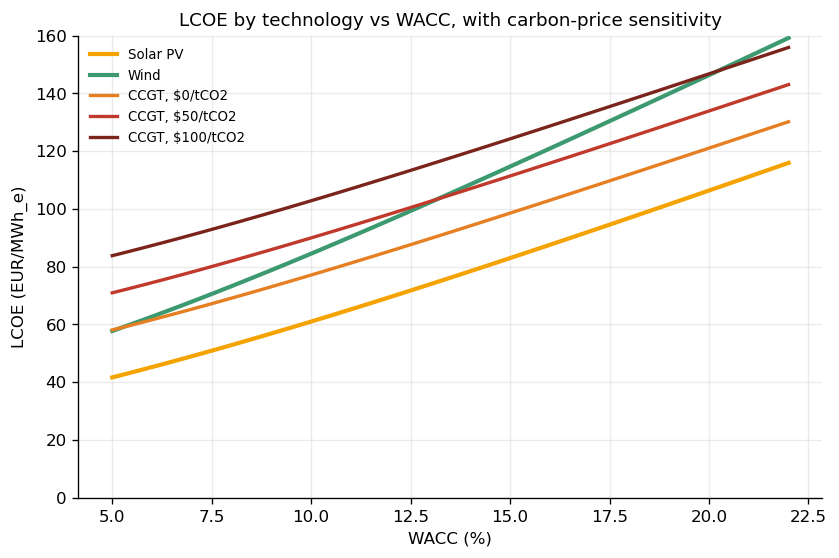

PosixPath('/Users/fowfloi/Documents/pypsa-earth/analysis/output/figures/lcoe_carbon_bands.pdf')

In [20]:
USD_TO_EUR = 0.7532

def annuity(r, n):
    return r / (1 - (1+r)**(-n))

def lcoe_tech(r, capex_eur_per_kw, fom_pct, vom, lifetime, cf, fuel=0, eff=1):
    capex = capex_eur_per_kw * 1e3
    annual = capex * annuity(r, lifetime) + fom_pct*capex
    var = vom + fuel/eff
    return annual / (cf*8760) + var

waccs = np.linspace(0.05, 0.22, 40)
solar  = [lcoe_tech(r, 814/0.7532, 0.0134, 0.015, 25, 0.25) for r in waccs]
wind   = [lcoe_tech(r, 1507/0.7532, 0.0234, 0.015, 30, 0.35) for r in waccs]

def ccgt(r, carbon_usd=0):
    fuel_eur = 9.614
    eff = 0.53
    carbon_eur = carbon_usd * 0.181 / eff * USD_TO_EUR
    return lcoe_tech(r, 1989/0.7532, 0.0121, 4.158, 30, 0.65, fuel=fuel_eur, eff=eff) + carbon_eur

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(100*waccs, solar, color=PALETTE['solar'], linewidth=2.5, label='Solar PV')
ax.plot(100*waccs, wind, color=PALETTE['onwind'], linewidth=2.5, label='Wind')
for cp, color in [(0,'#e67e22'),(50,'#c0392b'),(100,'#7b241c')]:
    y = [ccgt(r, cp) for r in waccs]
    ax.plot(100*waccs, y, color=color, linewidth=2, label=f'CCGT, ${cp}/tCO2')
    idx = np.argmin(np.abs(np.array(solar) - np.array(y)))
    if 0 < idx < len(waccs)-1:
        ax.plot([100*waccs[idx]], [solar[idx]], 'o', color=color, markersize=7)
        ax.annotate(f'{100*waccs[idx]:.1f}%', xy=(100*waccs[idx], solar[idx]),
                    xytext=(5,5), textcoords='offset points', fontsize=8, color=color)
ax.set_xlabel('WACC (%)')
ax.set_ylabel('LCOE (EUR/MWh_e)')
ax.set_title('LCOE by technology vs WACC, with carbon-price sensitivity')
ax.set_ylim(0, 160)
ax.legend(fontsize=8)
plt.show()
savefig(fig, 'lcoe_carbon_bands')

## Scratch — ad-hoc queries

In [21]:
# Cost of the NDC cap at matched WACC
pairs = [('config.nigeria.2030_C6_wacc_1379','config.nigeria.2030_D2_wacc_1379_ndc'),
         ('config.nigeria.2030_C10_wacc_2000','config.nigeria.2030_D3_wacc_2000_ndc')]
dfi = df.set_index('run_name')
for c,d in pairs:
    dc = (dfi.at[d,'objective'] - dfi.at[c,'objective'])/1e9
    de = dfi.at[c,'emissions_mt'] - dfi.at[d,'emissions_mt']
    print(f'{c} -> {d}: cost +{dc:.3f} bn EUR, abatement {de:.2f} Mt')

config.nigeria.2030_C6_wacc_1379 -> config.nigeria.2030_D2_wacc_1379_ndc: cost +0.017 bn EUR, abatement 0.45 Mt
config.nigeria.2030_C10_wacc_2000 -> config.nigeria.2030_D3_wacc_2000_ndc: cost +0.638 bn EUR, abatement 12.26 Mt
